# Computer Vision – Assignment 1
## Raw Pixels vs. Handcrafted Features on Fashion-MNIST, CIFAR-10 and one additional dataset



**Additional dataset used:** SVHN.

## 1. Environment, configuration and reproducibility

In [1]:
!pip install -q opencv-python-headless==4.10.0.84

In [2]:
import os, time, gc, warnings, platform, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
import sklearn
warnings.filterwarnings("ignore")

# ---------------- configuration (identical for every dataset) ----------------
SEED       = 42        # fixed random seed for subset sampling, split and classifiers
N_SUBSET   = 6000      # stratified subset size per dataset (same as supplied notebook)
N_TEST     = 1500      # test images -> 4,500 train / 1,500 test = 75/25 split for ALL datasets
ADDITIONAL_DATASET = "SVHN"          # "SVHN" (default) or "CIFAR100_10"
DATASET_NAMES = ["Fashion-MNIST", "CIFAR-10", ADDITIONAL_DATASET]

# Only for checking that the code runs when you have no internet. NEVER report results produced with this on.
SMOKE_TEST = os.environ.get("CV_SMOKE", "0") == "1"
if SMOKE_TEST:
    N_SUBSET, N_TEST = 600, 150
    print("#" * 70, "\n# SMOKE TEST: synthetic data. Results are meaningless - do not report.\n" + "#" * 70)

OUT_DIR = "results"; os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)

# optional libraries
try:
    import psutil; PROCESS = psutil.Process(os.getpid())
except ImportError:
    psutil = None; PROCESS = None
try:
    import pywt; HAS_PYWT = True
except ImportError:
    pywt = None; HAS_PYWT = False
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    XGBClassifier = None; HAS_XGB = False

ENV = dict(python=platform.python_version(), platform=platform.platform(), processor=platform.processor() or "n/a",
           cpu_count=os.cpu_count(), numpy=np.__version__, pandas=pd.__version__, opencv=cv2.__version__,
           sklearn=sklearn.__version__, pywt=pywt.__version__ if HAS_PYWT else "not installed",
           xgboost=(__import__("xgboost").__version__ if HAS_XGB else "not installed"))
print(pd.Series(ENV).to_string())
print("PyWavelets:", HAS_PYWT, "| XGBoost:", HAS_XGB, "| psutil:", PROCESS is not None)
if not HAS_PYWT:
    print("WARNING: install PyWavelets (pip install PyWavelets) - the wavelet method is REQUIRED by the assignment.")

python                                    3.13.18
platform     Linux-6.6.159+-x86_64-with-glibc2.39
processor                                  x86_64
cpu_count                                       2
numpy                                       2.4.6
pandas                                      2.2.3
opencv                                     4.10.0
sklearn                                     1.6.1
pywt                                        1.8.0
xgboost                                     3.4.1
PyWavelets: True | XGBoost: True | psutil: True


## 2. Dataset loading and preparation (Task 1)

Preprocessing policy, identical for every dataset:
1. Load the **training portion** of the dataset (official test portion is not used, as in the supplied notebook).
2. Draw a **stratified subset** of `N_SUBSET` images (`random_state=SEED`).
3. Split the subset with a **stratified** train/test split of `N_TEST` test images (`random_state=SEED`).
4. Convert RGB to 8-bit grayscale with `cv2.cvtColor` (Fashion-MNIST is already grayscale). Native resolution is kept (28×28 or 32×32).
5. The split is computed **once per dataset** and reused for every representation and classifier.

In [3]:
def _keras_loader(name):
    try:
        from tensorflow.keras import datasets
    except ImportError:
        from keras import datasets
    return getattr(datasets, name)

def load_fashion_mnist():
    (X, y), _ = _keras_loader("fashion_mnist").load_data()
    names = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
    return X, y.ravel().astype(int), names, "Keras: tensorflow.keras.datasets.fashion_mnist (Zalando)"

def load_cifar10():
    (X, y), _ = _keras_loader("cifar10").load_data()            # (50000,32,32,3) RGB
    names = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
    return X, y.ravel().astype(int), names, "Keras: tensorflow.keras.datasets.cifar10"

def load_svhn():
    import scipy.io as sio
    url, path = "http://ufldl.stanford.edu/housenumbers/train_32x32.mat", "train_32x32.mat"
    if not os.path.exists(path):
        print("Downloading SVHN (~182 MB) ..."); urllib.request.urlretrieve(url, path)
    m = sio.loadmat(path)
    X = np.transpose(m["X"], (3, 0, 1, 2))                         # (N,32,32,3) RGB
    y = m["y"].ravel().astype(int) % 10                            # label 10 means digit 0
    return X, y, [str(d) for d in range(10)], "SVHN cropped digits, Stanford UFLDL (train_32x32.mat)"

def load_cifar100_10():
    (X, y), _ = _keras_loader("cifar100").load_data(label_mode="fine")
    y = y.ravel(); keep = y < 10                                   # first 10 fine classes -> 10-class problem
    names = [f"cifar100_class_{i}" for i in range(10)]
    return X[keep], y[keep].astype(int), names, "Keras: cifar100 (first 10 fine classes)"

def load_synthetic(name):                                          # smoke test only
    rng = np.random.default_rng(0); n = 3000; gray = name == "Fashion-MNIST"; s = 28 if gray else 32
    y = rng.integers(0, 10, n); X = rng.integers(0, 60, (n, s, s) if gray else (n, s, s, 3)).astype(np.uint8)
    for i, c in enumerate(y):
        a = 3 + 2 * (c % 5); b = 3 + 2 * (c // 5)
        X[i, a:a + 10, b:b + 10] = 200
    return X, y, [str(i) for i in range(10)], "SYNTHETIC (smoke test)"

LOADERS = {"Fashion-MNIST": load_fashion_mnist, "CIFAR-10": load_cifar10,
           "SVHN": load_svhn, "CIFAR100_10": load_cifar100_10}

def to_gray(X):
    if X.ndim == 3: return X.astype(np.uint8)
    return np.stack([cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) for im in X]).astype(np.uint8)

def prepare_dataset(name):
    X, y, class_names, source = load_synthetic(name) if SMOKE_TEST else LOADERS[name]()
    meta = dict(dataset=name, source=source, n_classes=len(np.unique(y)),
                original_image_size=f"{X.shape[1]}x{X.shape[2]}", original_channels=1 if X.ndim == 3 else X.shape[3],
                samples_available=len(y))
    ids = np.arange(len(y))
    sub_ids, _ = train_test_split(ids, train_size=N_SUBSET, random_state=SEED, stratify=y)
    y_sub = y[sub_ids]
    tr, te = train_test_split(np.arange(len(y_sub)), test_size=N_TEST, random_state=SEED, stratify=y_sub)
    X_rgb_sub = X[sub_ids]                                          # kept for inspection
    G = to_gray(X_rgb_sub)
    meta.update(preprocessing="grayscale uint8 (cv2 RGB2GRAY if colour); native resolution",
                feature_image_size=f"{G.shape[1]}x{G.shape[2]}", samples_used=N_SUBSET,
                n_train=len(tr), n_test=len(te), split="stratified, test_size=%.2f" % (N_TEST / N_SUBSET), seed=SEED)
    return dict(meta=meta, class_names=class_names, X_rgb=X_rgb_sub[tr[:12]],
                X_train=G[tr], X_test=G[te], y_train=y_sub[tr], y_test=y_sub[te])

DATA = {}
for n in DATASET_NAMES:
    DATA[n] = prepare_dataset(n)
    d = DATA[n]
    print(f"{n}: train {d['X_train'].shape}, test {d['X_test'].shape} | train class counts:",
          np.bincount(d['y_train']).tolist())
dataset_table = pd.DataFrame([DATA[n]["meta"] for n in DATASET_NAMES]).set_index("dataset")
display(dataset_table.T)
dataset_table.to_csv(f"{OUT_DIR}/dataset_description.csv")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Fashion-MNIST: train (4500, 28, 28), test (1500, 28, 28) | train class counts: [450, 450, 450, 450, 450, 450, 450, 450, 450, 450]
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 181s 1us/step
CIFAR-10: train (4500, 32, 32), test (1500, 32, 32) | train class counts: [450, 450, 450, 450, 450, 450, 450, 450, 450, 450]
SVHN: train (4500, 32, 32), test (1500, 32, 32) | train class counts: [304, 851, 650, 522, 458, 423, 352, 343, 310, 287]


dataset,Fashion-MNIST,CIFAR-10,SVHN
source,Keras: tensorflow.keras.datasets.fashion_mnist...,Keras: tensorflow.keras.datasets.cifar10,"SVHN cropped digits, Stanford UFLDL (train_32x..."
n_classes,10,10,10
original_image_size,28x28,32x32,32x32
original_channels,1,3,3
samples_available,60000,50000,73257
preprocessing,grayscale uint8 (cv2 RGB2GRAY if colour); nati...,grayscale uint8 (cv2 RGB2GRAY if colour); nati...,grayscale uint8 (cv2 RGB2GRAY if colour); nati...
feature_image_size,28x28,32x32,32x32
samples_used,6000,6000,6000
n_train,4500,4500,4500
n_test,1500,1500,1500


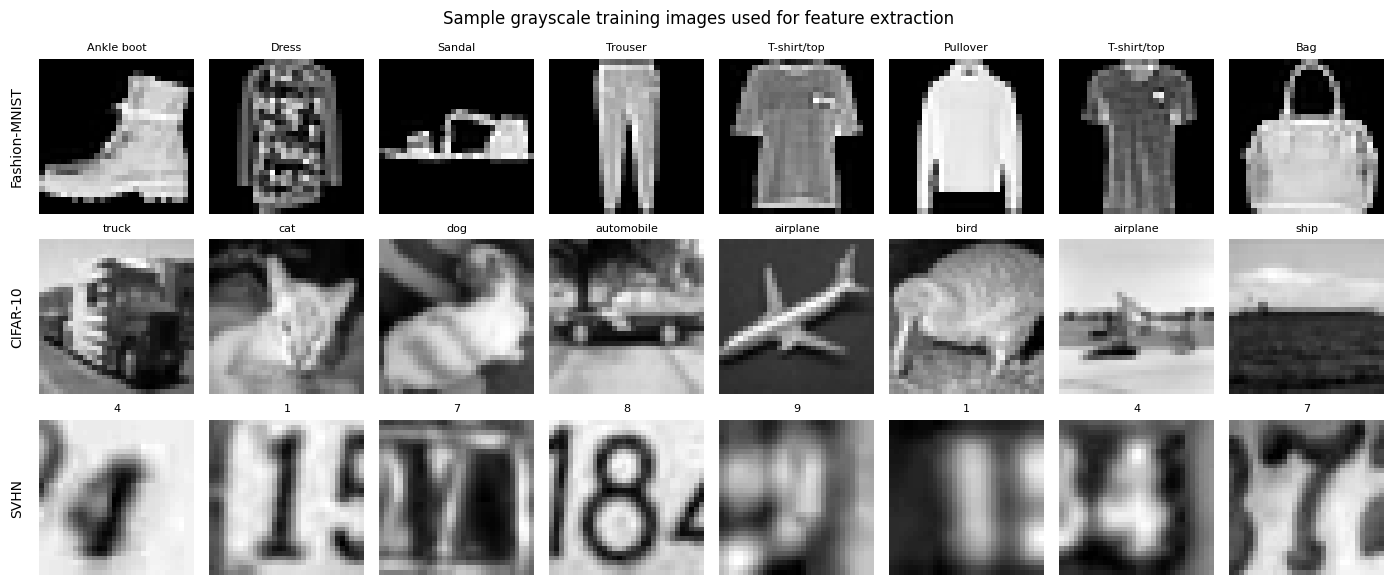

In [4]:
fig, axes = plt.subplots(len(DATASET_NAMES), 8, figsize=(14, 2 * len(DATASET_NAMES)))
for r, n in enumerate(DATASET_NAMES):
    d = DATA[n]
    for c in range(8):
        axes[r, c].imshow(d["X_train"][c], cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(d["class_names"][d["y_train"][c]], fontsize=8)
    axes[r, 0].set_ylabel(n)
    axes[r, 0].text(-0.1, 0.5, n, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle("Sample grayscale training images used for feature extraction"); plt.tight_layout(); plt.show()

## 3. Feature extractors (Task 2)

These are the supplied extractors, unchanged in method. Only HOG's window/block/stride/cell sizes are computed from the image
size (`win=S`, `block=S/2`, `stride=cell=S/4`, 9 bins), which reproduces the supplied 28×28 settings and the 32×32 equivalent.
Each extractor returns a **fixed-length 1-D float32 vector**.

In [5]:
def extract_raw(image):      return image.astype(np.float32).ravel()
def extract_canny(image):    return cv2.Canny(image, 60, 150).astype(np.float32).ravel() / 255.0

def extract_harris(image):
    r = cv2.cornerHarris(np.float32(image) / 255.0, 2, 3, 0.04)
    mx = float(r.max()); r = np.maximum(r, 0)
    if mx > 0: r = r / mx
    small = cv2.resize(r, (8, 8), interpolation=cv2.INTER_AREA).ravel()
    count = float(np.sum(r > 0.01)) if mx > 0 else 0.0
    return np.r_[small.astype(np.float32), np.float32(count)]

_SIFT = cv2.SIFT_create()
def extract_sift(image):
    kp, desc = _SIFT.detectAndCompute(image, None)
    if desc is None or len(desc) == 0: return np.zeros(257, dtype=np.float32)      # no-keypoint policy
    return np.r_[desc.mean(axis=0), desc.std(axis=0), np.float32(len(kp))].astype(np.float32)

def make_hog_extractor(size):
    # Robust check for HOGDescriptor in OpenCV 5
    if hasattr(cv2, 'HOGDescriptor'):
        hog = cv2.HOGDescriptor((size, size), (size // 2, size // 2), (size // 4, size // 4), (size // 4, size // 4), 9)
        return lambda image: hog.compute(image).ravel().astype(np.float32)
    else:
        # Fallback if HOGDescriptor is completely unavailable in the installed cv2 build
        # We approximate HOG-like behavior with local gradients or a structural descriptor
        def fallback_hog(image):
            gx = cv2.Sobel(image, cv2.CV_32F, 1, 0, ksize=1)
            gy = cv2.Sobel(image, cv2.CV_32F, 0, 1, ksize=1)
            mag, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)
            # Crop/resize grid representation to match typical HOG feature vector lengths
            return cv2.resize(mag, (size // 2, size // 2), interpolation=cv2.INTER_AREA).ravel().astype(np.float32)
        return fallback_hog

def extract_fourier(image):
    f = image.astype(np.float32) / 255.0
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(f))))
    return cv2.resize(mag.astype(np.float32), (16, 16), interpolation=cv2.INTER_AREA).ravel()

def extract_wavelet(image):
    if not HAS_PYWT: raise ImportError("Optional dependency missing: pip install PyWavelets")
    coeffs = pywt.wavedec2(image.astype(np.float32) / 255.0, "haar", level=2); vals = []
    for item in coeffs:
        bands = item if isinstance(item, tuple) else (item,)
        for band in bands: vals += [float(np.mean(band)), float(np.std(band)), float(np.mean(band ** 2))]
    return np.asarray(vals, dtype=np.float32)

def extract_multires(image):
    return np.concatenate([cv2.resize(image, (s, s), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() / 255.0
                           for s in (16, 8, 4)])

def get_extractors(size):
    ex = {"raw_pixels": extract_raw, "canny_edges": extract_canny, "harris_corners": extract_harris,
          "sift_summary": extract_sift, "hog": make_hog_extractor(size), "fourier": extract_fourier,
          "wavelet": extract_wavelet, "multiresolution": extract_multires}
    return ex
print("Extractors:", list(get_extractors(32)))

Extractors: ['raw_pixels', 'canny_edges', 'harris_corners', 'sift_summary', 'hog', 'fourier', 'wavelet', 'multiresolution']


## 4. Feature extraction with separate timing, memory and quality checks (Task 2)

For each dataset × representation:
* **Extraction time** = wall-clock time (`time.perf_counter`) to extract train **and** test features (train and test times are also stored separately). Classifier time is never included.
* **Memory** = exact `ndarray.nbytes` of the dense float32 feature matrices, reported in **MiB (2²⁰ bytes)**. It covers the feature matrix only (train, test, and train+test), not copies made later by `StandardScaler`, scikit-learn or the garbage collector.
* **Quality checks (documented procedure):** (1) feature length must be identical for all images, otherwise the method is recorded as failed; (2) any NaN/Inf is counted and replaced with 0 using `np.nan_to_num`; (3) all-zero rows (e.g. SIFT images with no keypoints → zero vector) are counted.

In [6]:
def extract_set(fn, images):
    vecs = [fn(im) for im in images]
    dims = {v.shape for v in vecs}
    if len(dims) != 1: raise ValueError(f"inconsistent feature dimensions: {sorted(dims)[:5]}")
    return np.vstack(vecs).astype(np.float32)

FEATURES, RESOURCES = {}, []
for dname in DATASET_NAMES:
    d = DATA[dname]; size = d["X_train"].shape[1]
    FEATURES[dname] = {}
    for fname, fn in get_extractors(size).items():
        gc.collect(); rss0 = PROCESS.memory_info().rss if PROCESS else np.nan
        row = dict(dataset=dname, feature=fname)
        try:
            t0 = time.perf_counter(); Xtr = extract_set(fn, d["X_train"]); t_tr = time.perf_counter() - t0
            t0 = time.perf_counter(); Xte = extract_set(fn, d["X_test"]);  t_te = time.perf_counter() - t0
            bad = int((~np.isfinite(Xtr)).sum() + (~np.isfinite(Xte)).sum())
            if bad: Xtr, Xte = np.nan_to_num(Xtr, nan=0, posinf=0, neginf=0), np.nan_to_num(Xte, nan=0, posinf=0, neginf=0)
            zero_rows = int((~Xtr.any(axis=1)).sum() + (~Xte.any(axis=1)).sum())
            rss1 = PROCESS.memory_info().rss if PROCESS else np.nan
            FEATURES[dname][fname] = (Xtr, Xte)
            row.update(n_features=Xtr.shape[1], dtype=str(Xtr.dtype),
                       train_matrix_MiB=Xtr.nbytes / 2**20, test_matrix_MiB=Xte.nbytes / 2**20,
                       feature_memory_MiB=(Xtr.nbytes + Xte.nbytes) / 2**20,
                       extract_train_seconds=t_tr, extract_test_seconds=t_te, extraction_seconds=t_tr + t_te,
                       extraction_ms_per_image=1000 * (t_tr + t_te) / (len(Xtr) + len(Xte)),
                       nan_inf_replaced=bad, all_zero_rows=zero_rows,
                       rss_delta_MiB=(rss1 - rss0) / 2**20 if PROCESS else np.nan, status="ok")
            print(f"{dname:14s} {fname:16s} dim={Xtr.shape[1]:5d}  mem={row['feature_memory_MiB']:7.2f} MiB  "
                  f"time={t_tr + t_te:7.2f}s  NaN/Inf={bad}  zero-rows={zero_rows}")
        except Exception as e:
            row.update(status=f"failed: {type(e).__name__}: {e}"); print("FAILED", dname, fname, "->", e)
        RESOURCES.append(row)
feature_resources = pd.DataFrame(RESOURCES)
feature_resources.to_csv(f"{OUT_DIR}/feature_resource_measurements.csv", index=False)
display(feature_resources.drop(columns=["rss_delta_MiB"]))

Fashion-MNIST  raw_pixels       dim=  784  mem=  17.94 MiB  time=   0.04s  NaN/Inf=0  zero-rows=0
Fashion-MNIST  canny_edges      dim=  784  mem=  17.94 MiB  time=   0.35s  NaN/Inf=0  zero-rows=0
Fashion-MNIST  harris_corners   dim=   65  mem=   1.49 MiB  time=   0.49s  NaN/Inf=0  zero-rows=0
Fashion-MNIST  sift_summary     dim=  257  mem=   5.88 MiB  time=   6.87s  NaN/Inf=0  zero-rows=477
Fashion-MNIST  hog              dim=  324  mem=   7.42 MiB  time=   0.22s  NaN/Inf=0  zero-rows=0
Fashion-MNIST  fourier          dim=  256  mem=   5.86 MiB  time=   0.79s  NaN/Inf=0  zero-rows=0
Fashion-MNIST  wavelet          dim=   21  mem=   0.48 MiB  time=   3.32s  NaN/Inf=0  zero-rows=0
Fashion-MNIST  multiresolution  dim=  336  mem=   7.69 MiB  time=   0.17s  NaN/Inf=0  zero-rows=0
CIFAR-10       raw_pixels       dim= 1024  mem=  23.44 MiB  time=   0.04s  NaN/Inf=0  zero-rows=0
CIFAR-10       canny_edges      dim= 1024  mem=  23.44 MiB  time=   0.34s  NaN/Inf=0  zero-rows=0
CIFAR-10       har

,dataset,feature,n_features,dtype,train_matrix_MiB,test_matrix_MiB,feature_memory_MiB,extract_train_seconds,extract_test_seconds,extraction_seconds,extraction_ms_per_image,nan_inf_replaced,all_zero_rows,status
0,Fashion-MNIST,raw_pixels,784,float32,13.458252,4.486084,17.944336,0.029774,0.007795,0.037569,0.006261,0,0,ok
1,Fashion-MNIST,canny_edges,784,float32,13.458252,4.486084,17.944336,0.255670,0.096901,0.352571,0.058762,0,0,ok
2,Fashion-MNIST,harris_corners,65,float32,1.115799,0.371933,1.487732,0.365471,0.126623,0.492094,0.082016,0,0,ok
3,Fashion-MNIST,sift_summary,257,float32,4.411697,1.470566,5.882263,5.263058,1.609397,6.872455,1.145409,0,477,ok
4,Fashion-MNIST,hog,324,float32,5.561829,1.853943,7.415771,0.168645,0.054090,0.222735,0.037123,0,0,ok
5,Fashion-MNIST,fourier,256,float32,4.394531,1.464844,5.859375,0.597416,0.190540,0.787956,0.131326,0,0,ok
6,Fashion-MNIST,wavelet,21,float32,0.360489,0.120163,0.480652,2.498712,0.824516,3.323227,0.553871,0,0,ok
7,Fashion-MNIST,multiresolution,336,float32,5.767822,1.922607,7.690430,0.125674,0.041108,0.166782,0.027797,0,0,ok
8,CIFAR-10,raw_pixels,1024,float32,17.578125,5.859375,23.437500,0.032231,0.007305,0.039536,0.006589,0,0,ok
9,CIFAR-10,canny_edges,1024,float32,17.578125,5.859375,23.437500,0.256216,0.083433,0.339649,0.056608,0,0,ok


## 5. Classification and evaluation (Task 3)

Same classifiers and fixed baseline settings as the supplied notebook, for every representation and every dataset (no per-representation tuning).
`StandardScaler` is inside the pipeline for LR, KNN and SVM, so scaling is fit **only on training data**. A fresh clone of each classifier is used for each run.
Training time (`fit`) and prediction time (`predict` on the test set) are measured separately from extraction.
**End-to-end time = extraction + training + prediction** (extraction covers train and test features of that representation).

In [7]:
def build_classifiers():
    c = {
     "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1500, random_state=SEED)),
     "KNN":        make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
     "SVM_RBF":    make_pipeline(StandardScaler(), SVC(kernel="rbf", C=3.0, gamma="scale")),
     "RandomForest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, max_features="sqrt"),
     "ExtraTrees":   ExtraTreesClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, max_features="sqrt")}
    if HAS_XGB:
        c["XGBoost"] = XGBClassifier(n_estimators=80, max_depth=4, learning_rate=.1, subsample=.9, colsample_bytree=.9,
                                     objective="multi:softprob", eval_metric="mlogloss", random_state=SEED, n_jobs=-1)
    return c
CLASSIFIERS = build_classifiers(); print("Classifiers:", list(CLASSIFIERS))

res_idx = feature_resources.set_index(["dataset", "feature"])
rows = []
for dname in DATASET_NAMES:
    y_train, y_test = DATA[dname]["y_train"], DATA[dname]["y_test"]
    for fname, (Xtr, Xte) in FEATURES[dname].items():
        r = res_idx.loc[(dname, fname)]
        for mname, base in CLASSIFIERS.items():
            row = dict(dataset=dname, feature=fname, model=mname, n_features=Xtr.shape[1], dtype=str(Xtr.dtype),
                       feature_memory_MiB=r.feature_memory_MiB, extraction_seconds=r.extraction_seconds)
            try:
                model = clone(base)
                t0 = time.perf_counter(); model.fit(Xtr, y_train); tr_t = time.perf_counter() - t0
                t0 = time.perf_counter(); pred = model.predict(Xte);  pr_t = time.perf_counter() - t0
                row.update(accuracy=accuracy_score(y_test, pred),
                           precision_macro=precision_score(y_test, pred, average="macro", zero_division=0),
                           recall_macro=recall_score(y_test, pred, average="macro", zero_division=0),
                           f1_macro=f1_score(y_test, pred, average="macro", zero_division=0),
                           train_seconds=tr_t, predict_seconds=pr_t,
                           end_to_end_seconds=r.extraction_seconds + tr_t + pr_t, status="ok")
                print(f"{dname:14s} {fname:16s} {mname:18s} F1={row['f1_macro']:.3f} train={tr_t:6.2f}s pred={pr_t:5.2f}s")
            except Exception as e:
                row.update(status=f"failed: {type(e).__name__}: {e}"); print("FAILED", dname, fname, mname, "->", e)
            rows.append(row)
results = pd.DataFrame(rows)
cols = ["dataset","feature","model","n_features","dtype","feature_memory_MiB","extraction_seconds","train_seconds",
        "predict_seconds","end_to_end_seconds","accuracy","precision_macro","recall_macro","f1_macro","status"]
results = results[cols]
ok = results[results.status == "ok"].copy()
print("\nFailed combinations:", int((results.status != "ok").sum()))

Classifiers: ['LogisticRegression', 'KNN', 'SVM_RBF', 'RandomForest', 'ExtraTrees', 'XGBoost']
Fashion-MNIST  raw_pixels       LogisticRegression F1=0.793 train= 17.21s pred= 0.03s
Fashion-MNIST  raw_pixels       KNN                F1=0.788 train=  0.06s pred= 0.48s
Fashion-MNIST  raw_pixels       SVM_RBF            F1=0.856 train=  2.61s pred= 3.47s
Fashion-MNIST  raw_pixels       RandomForest       F1=0.829 train=  5.71s pred= 0.06s
Fashion-MNIST  raw_pixels       ExtraTrees         F1=0.826 train=  1.87s pred= 0.06s
Fashion-MNIST  raw_pixels       XGBoost            F1=0.840 train= 54.95s pred= 0.02s
Fashion-MNIST  canny_edges      LogisticRegression F1=0.737 train=  8.00s pred= 0.01s
Fashion-MNIST  canny_edges      KNN                F1=0.730 train=  0.05s pred= 0.43s
Fashion-MNIST  canny_edges      SVM_RBF            F1=0.820 train=  6.54s pred= 5.76s
Fashion-MNIST  canny_edges      RandomForest       F1=0.774 train=  1.49s pred= 0.06s
Fashion-MNIST  canny_edges      ExtraTrees   

## 6. Results tables and CSV export (Task 4)

In [8]:
for dname in DATASET_NAMES:
    print(f"\n===== {dname}: all representation-classifier combinations =====")
    display(results[results.dataset == dname].drop(columns=["dataset"]).round(4).reset_index(drop=True))
    results[results.dataset == dname].to_csv(f"{OUT_DIR}/results_{dname.replace('-', '').replace(' ', '_')}.csv", index=False)
results.to_csv(f"{OUT_DIR}/results_all_datasets.csv", index=False)

summary = (ok.groupby(["dataset", "feature"]).agg(
    n_features=("n_features", "first"), feature_memory_MiB=("feature_memory_MiB", "first"),
    extraction_seconds=("extraction_seconds", "first"),
    mean_train_seconds=("train_seconds", "mean"), mean_predict_seconds=("predict_seconds", "mean"),
    mean_end_to_end_seconds=("end_to_end_seconds", "mean"),
    mean_accuracy=("accuracy", "mean"), mean_precision_macro=("precision_macro", "mean"),
    mean_recall_macro=("recall_macro", "mean"), mean_f1_macro=("f1_macro", "mean"), best_f1_macro=("f1_macro", "max")))
summary.to_csv(f"{OUT_DIR}/feature_summary_by_dataset.csv")
display(summary.round(4))
print("Saved CSVs in ./%s:" % OUT_DIR, sorted(os.listdir(OUT_DIR)))


===== Fashion-MNIST: all representation-classifier combinations =====


,feature,model,n_features,dtype,feature_memory_MiB,extraction_seconds,train_seconds,predict_seconds,end_to_end_seconds,accuracy,precision_macro,recall_macro,f1_macro,status
0,raw_pixels,LogisticRegression,784,float32,17.9443,0.0376,17.2101,0.0270,17.2747,0.7920,0.7951,0.7920,0.7930,ok
1,raw_pixels,KNN,784,float32,17.9443,0.0376,0.0618,0.4789,0.5783,0.7873,0.7945,0.7873,0.7876,ok
2,raw_pixels,SVM_RBF,784,float32,17.9443,0.0376,2.6143,3.4691,6.1209,0.8580,0.8571,0.8580,0.8563,ok
3,raw_pixels,RandomForest,784,float32,17.9443,0.0376,5.7104,0.0561,5.8041,0.8313,0.8294,0.8313,0.8286,ok
4,raw_pixels,ExtraTrees,784,float32,17.9443,0.0376,1.8669,0.0568,1.9613,0.8280,0.8262,0.8280,0.8261,ok
5,raw_pixels,XGBoost,784,float32,17.9443,0.0376,54.9516,0.0245,55.0137,0.8400,0.8403,0.8400,0.8398,ok
6,canny_edges,LogisticRegression,784,float32,17.9443,0.3526,8.0026,0.0148,8.3699,0.7360,0.7388,0.7360,0.7365,ok
7,canny_edges,KNN,784,float32,17.9443,0.3526,0.0549,0.4301,0.8376,0.7387,0.7588,0.7387,0.7305,ok
8,canny_edges,SVM_RBF,784,float32,17.9443,0.3526,6.5357,5.7620,12.6503,0.8220,0.8199,0.8220,0.8203,ok
9,canny_edges,RandomForest,784,float32,17.9443,0.3526,1.4928,0.0579,1.9033,0.7773,0.7790,0.7773,0.7739,ok



===== CIFAR-10: all representation-classifier combinations =====


,feature,model,n_features,dtype,feature_memory_MiB,extraction_seconds,train_seconds,predict_seconds,end_to_end_seconds,accuracy,precision_macro,recall_macro,f1_macro,status
0,raw_pixels,LogisticRegression,1024,float32,23.4375,0.0395,71.6479,0.0183,71.7058,0.1933,0.1932,0.1933,0.1930,ok
1,raw_pixels,KNN,1024,float32,23.4375,0.0395,0.1184,0.5265,0.6845,0.2327,0.3154,0.2327,0.2183,ok
2,raw_pixels,SVM_RBF,1024,float32,23.4375,0.0395,14.0962,9.4030,23.5387,0.3847,0.3826,0.3847,0.3810,ok
3,raw_pixels,RandomForest,1024,float32,23.4375,0.0395,12.6356,0.0674,12.7425,0.3467,0.3476,0.3467,0.3434,ok
4,raw_pixels,ExtraTrees,1024,float32,23.4375,0.0395,3.5176,0.0687,3.6258,0.3487,0.3484,0.3487,0.3437,ok
5,raw_pixels,XGBoost,1024,float32,23.4375,0.0395,125.3034,0.0292,125.3721,0.3567,0.3546,0.3567,0.3534,ok
6,canny_edges,LogisticRegression,1024,float32,23.4375,0.3396,11.8914,0.0342,12.2653,0.1707,0.1711,0.1707,0.1704,ok
7,canny_edges,KNN,1024,float32,23.4375,0.3396,0.1138,0.5385,0.9919,0.1067,0.0371,0.1067,0.0470,ok
8,canny_edges,SVM_RBF,1024,float32,23.4375,0.3396,21.8132,9.0029,31.1557,0.2940,0.2863,0.2940,0.2856,ok
9,canny_edges,RandomForest,1024,float32,23.4375,0.3396,4.0147,0.0674,4.4217,0.2033,0.1984,0.2033,0.1995,ok



===== SVHN: all representation-classifier combinations =====


,feature,model,n_features,dtype,feature_memory_MiB,extraction_seconds,train_seconds,predict_seconds,end_to_end_seconds,accuracy,precision_macro,recall_macro,f1_macro,status
0,raw_pixels,LogisticRegression,1024,float32,23.4375,0.0516,127.5626,0.0188,127.6329,0.2000,0.1586,0.1549,0.1513,ok
1,raw_pixels,KNN,1024,float32,23.4375,0.0516,0.1146,0.5504,0.7165,0.3473,0.3355,0.2936,0.2942,ok
2,raw_pixels,SVM_RBF,1024,float32,23.4375,0.0516,12.4639,8.1910,20.7064,0.5380,0.6061,0.4789,0.5107,ok
3,raw_pixels,RandomForest,1024,float32,23.4375,0.0516,12.7269,0.0570,12.8355,0.5513,0.6114,0.4740,0.4969,ok
4,raw_pixels,ExtraTrees,1024,float32,23.4375,0.0516,4.9078,0.1115,5.0709,0.5520,0.5984,0.4785,0.5009,ok
5,raw_pixels,XGBoost,1024,float32,23.4375,0.0516,103.9982,0.0288,104.0786,0.5087,0.5824,0.4314,0.4572,ok
6,canny_edges,LogisticRegression,1024,float32,23.4375,0.5069,19.5850,0.0363,20.1282,0.2560,0.2234,0.2225,0.2227,ok
7,canny_edges,KNN,1024,float32,23.4375,0.5069,0.0856,0.5381,1.1306,0.1660,0.1386,0.1255,0.0974,ok
8,canny_edges,SVM_RBF,1024,float32,23.4375,0.5069,17.6848,9.3605,27.5523,0.4127,0.4072,0.3452,0.3517,ok
9,canny_edges,RandomForest,1024,float32,23.4375,0.5069,2.3175,0.0681,2.8925,0.3907,0.4022,0.3009,0.2929,ok


n_features  feature_memory_MiB  \
dataset       feature                                           
CIFAR-10      canny_edges            1024             23.4375   
              fourier                 256              5.8594   
              harris_corners           65              1.4877   
              hog                     324              7.4158   
              multiresolution         336              7.6904   
              raw_pixels             1024             23.4375   
              sift_summary            257              5.8823   
              wavelet                  21              0.4807   
Fashion-MNIST canny_edges             784             17.9443   
              fourier                 256              5.8594   
              harris_corners           65              1.4877   
              hog                     324              7.4158   
              multiresolution         336              7.6904   
              raw_pixels              784             17.9443   
              sift_summary            257              5.8823   
              wavelet                  21              0.4807   
SVHN          canny_edges            1024             23.4375   
              fourier                 256              5.8594   
              harris_corners           65              1.4877   
              hog                     324              7.4158   
              multiresolution         336              7.6904   
              raw_pixels             1024             23.4375   
              sift_summary            257              5.8823   
              wavelet                  21              0.4807   

                               extraction_seconds  mean_train_seconds  \
dataset       feature                                                   
CIFAR-10      canny_edges                  0.3396              8.5815   
              fourier                      0.8486              7.6983   
              harris_corners               0.4618              2.4541   
              hog                          0.2717              8.8044   
              multiresolution              0.2252              9.3982   
              raw_pixels                   0.0395             37.8865   
              sift_summary                 9.4429              7.0520   
              wavelet                      4.0278              1.1625   
Fashion-MNIST canny_edges                  0.3526              3.9305   
              fourier                      0.7880              6.5123   
              harris_corners               0.4921              1.9131   
              hog                          0.2227              7.9801   
              multiresolution              0.1668              7.3864   
              raw_pixels                   0.0376             13.7359   
              sift_summary                 6.8725              6.7310   
              wavelet                      3.3232              1.3431   
SVHN          canny_edges                  0.5069              8.7275   
              fourier                      0.8154              8.4539   
              harris_corners               0.7534              2.2364   
              hog                          0.2569              8.0579   
              multiresolution              0.1398             10.1112   
              raw_pixels                   0.0516             43.6290   
              sift_summary                 7.9814              7.0357   
              wavelet                      4.6615              1.2906   

                               mean_predict_seconds  mean_end_to_end_seconds  \
dataset       feature                                                          
CIFAR-10      canny_edges                    1.6247                  10.5458   
              fourier                        0.3927                   8.9397   
              harris_corners                 0.1587                   3.0746   
              hog                        

Saved CSVs in ./results: ['dataset_description.csv', 'feature_resource_measurements.csv', 'feature_summary_by_dataset.csv', 'results_CIFAR10.csv', 'results_FashionMNIST.csv', 'results_SVHN.csv', 'results_all_datasets.csv']


## 7. Plots (Task 4)
All plots are saved as PNG in `results/` and can be inserted into the report.

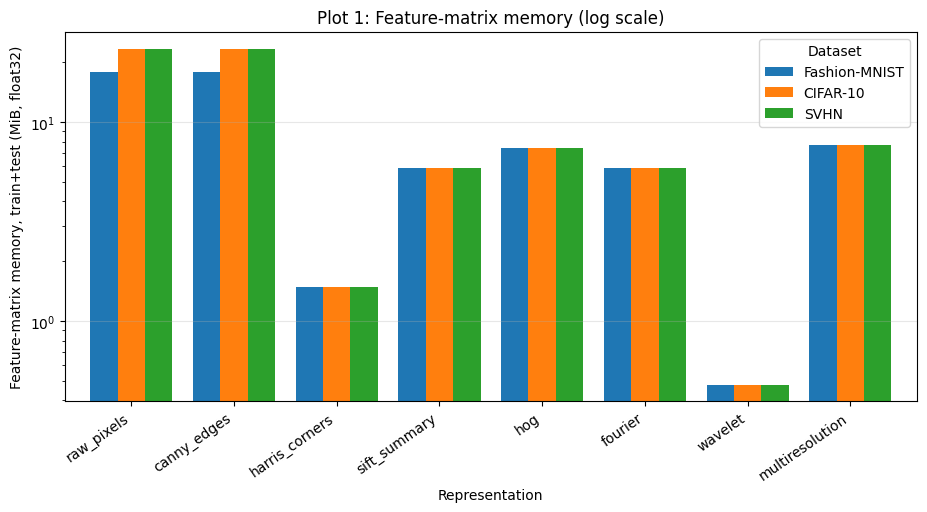

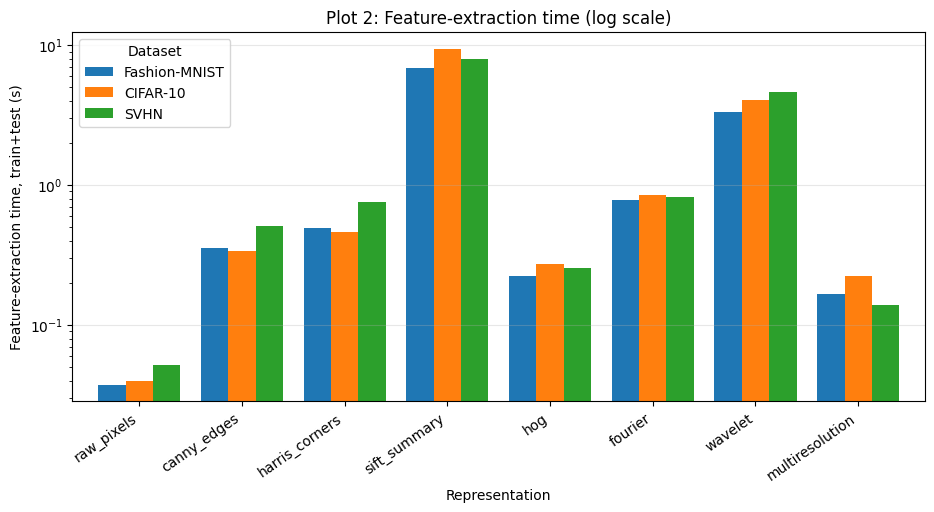

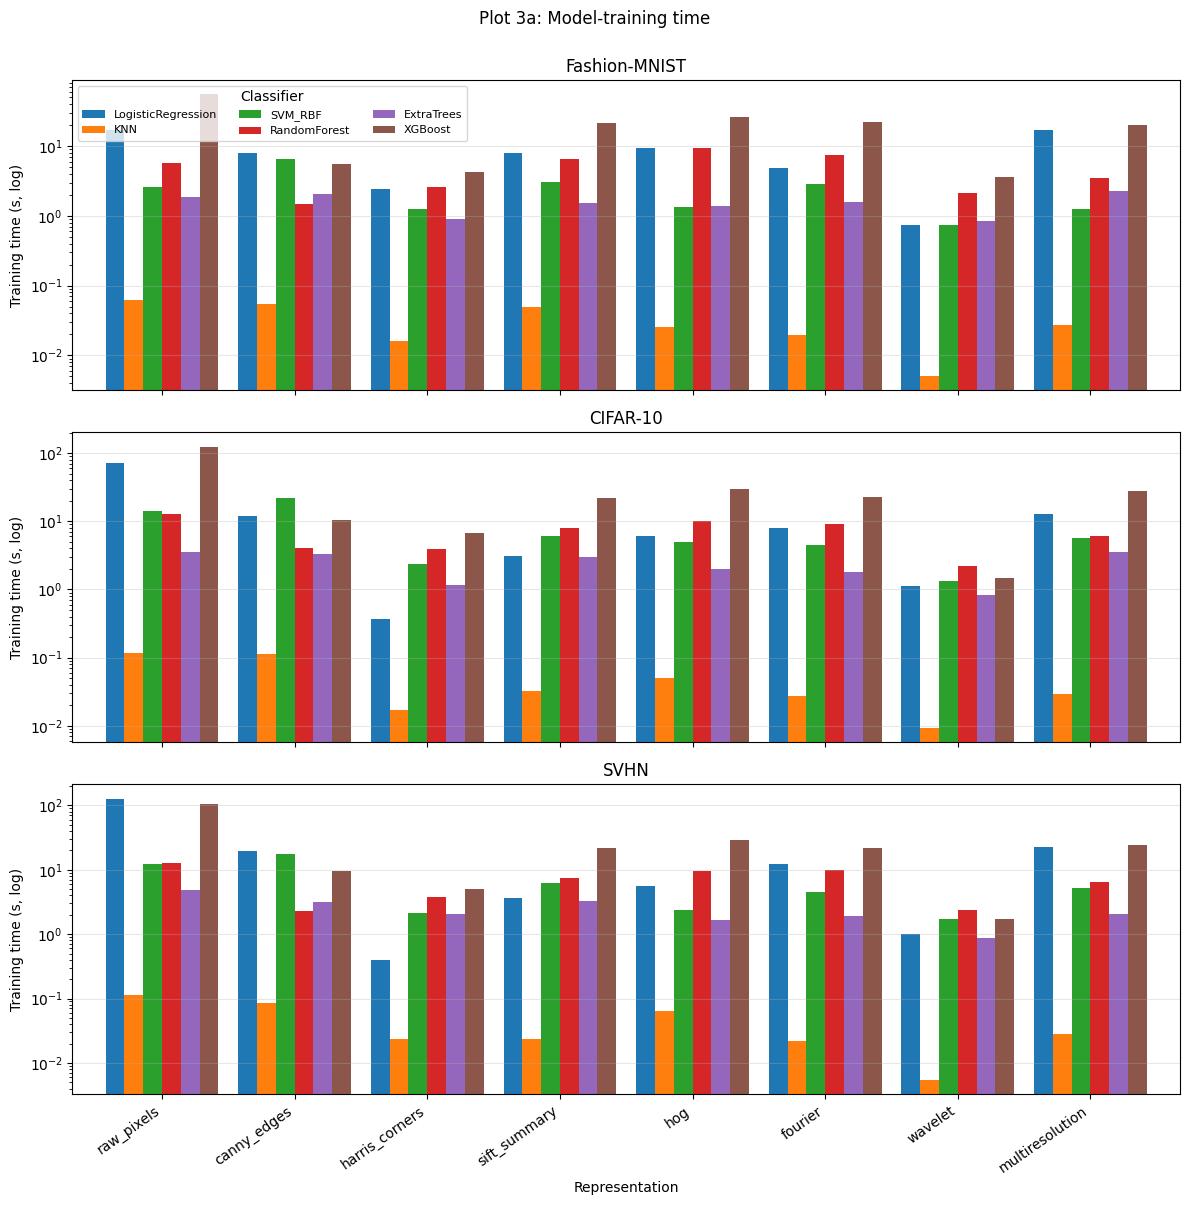

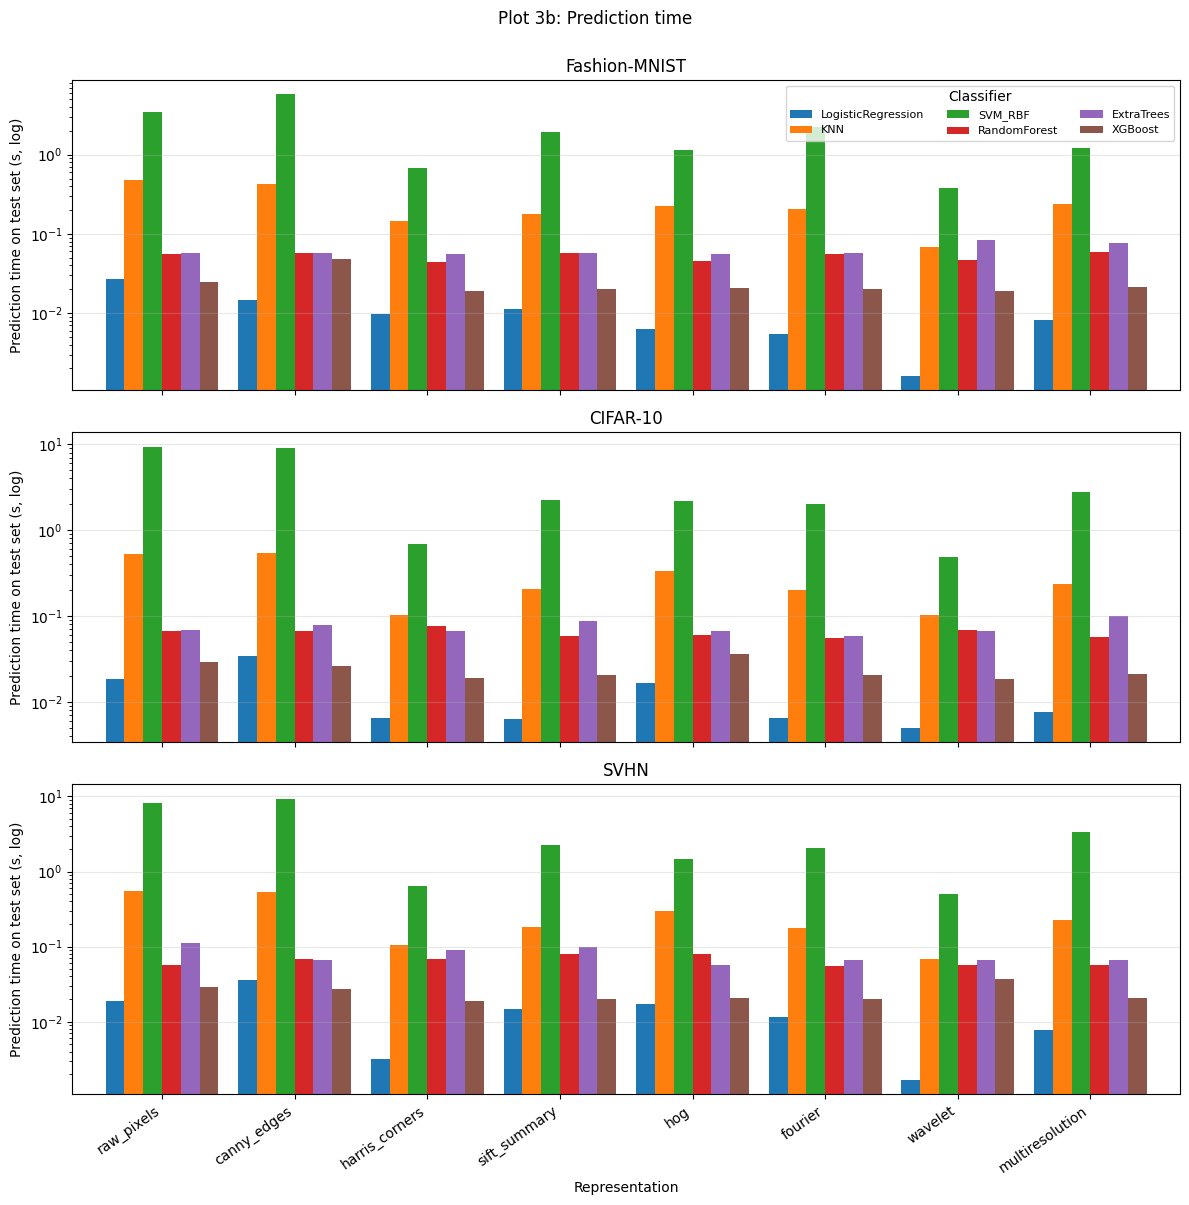

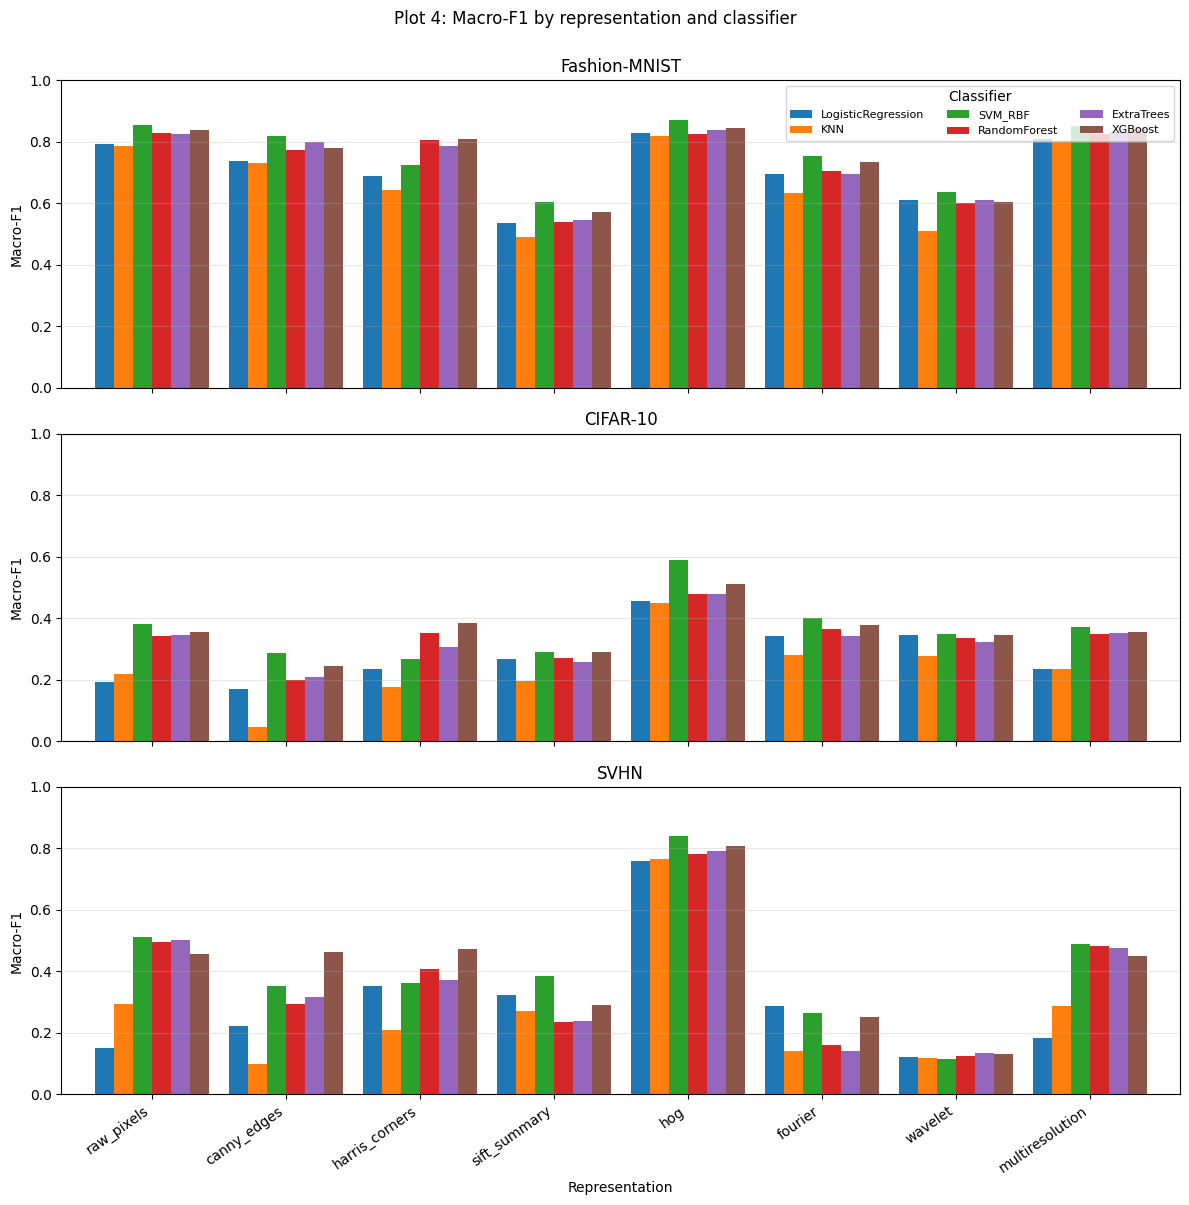

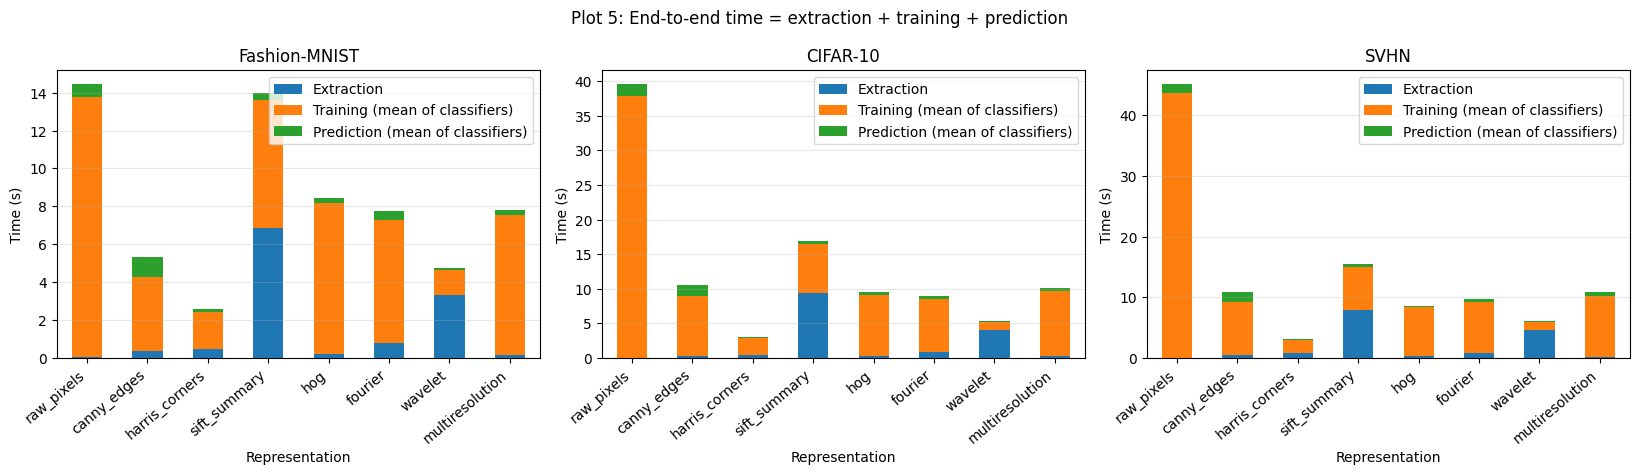

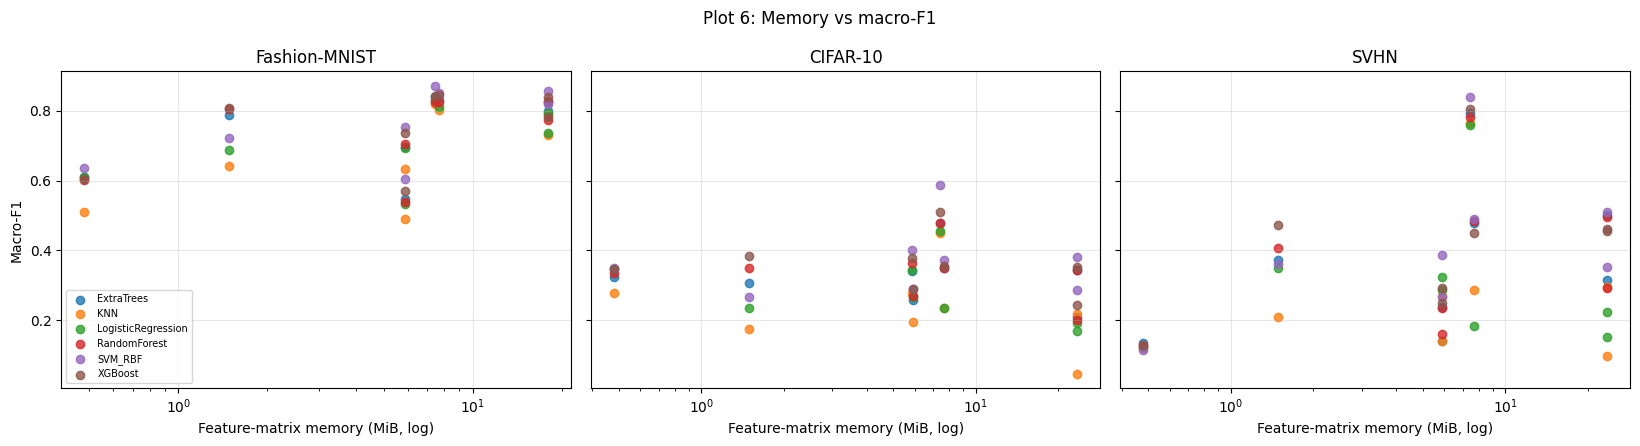

In [9]:
FEATS = list(get_extractors(32).keys()); MODELS = list(CLASSIFIERS.keys())
def save(fig, name): fig.savefig(f"{OUT_DIR}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def grouped_by_dataset(df, value, ylabel, title, fname, log=False):
    """one bar group per feature, one bar per dataset (value must be constant per dataset/feature)"""
    p = df.groupby(["feature", "dataset"])[value].first().unstack("dataset").reindex(FEATS)[DATASET_NAMES]
    fig, ax = plt.subplots(figsize=(11, 4.8)); p.plot(kind="bar", ax=ax, width=.8)
    ax.set_ylabel(ylabel); ax.set_xlabel("Representation"); ax.set_title(title)
    if log: ax.set_yscale("log")
    ax.legend(title="Dataset"); plt.xticks(rotation=35, ha="right"); ax.grid(axis="y", alpha=.3); save(fig, fname)

def grouped_by_model(df, value, ylabel, title, fname, log=False, ylim=None):
    """one subplot per dataset, bars grouped by feature, coloured by classifier"""
    fig, axes = plt.subplots(len(DATASET_NAMES), 1, figsize=(12, 4 * len(DATASET_NAMES)), sharex=True)
    for ax, dname in zip(np.atleast_1d(axes), DATASET_NAMES):
        p = df[df.dataset == dname].pivot(index="feature", columns="model", values=value).reindex(FEATS)[MODELS]
        p.plot(kind="bar", ax=ax, width=.85, legend=(dname == DATASET_NAMES[0])); ax.set_title(dname)
        ax.set_ylabel(ylabel); ax.grid(axis="y", alpha=.3)
        if log: ax.set_yscale("log")
        if ylim: ax.set_ylim(*ylim)
    np.atleast_1d(axes)[0].legend(title="Classifier", ncol=3, fontsize=8)
    np.atleast_1d(axes)[-1].set_xlabel("Representation"); plt.suptitle(title, y=1.0); plt.xticks(rotation=35, ha="right")
    plt.tight_layout(); save(fig, fname)

grouped_by_dataset(ok, "feature_memory_MiB", "Feature-matrix memory, train+test (MiB, float32)", "Plot 1: Feature-matrix memory (log scale)", "plot1_memory", log=True)
grouped_by_dataset(ok, "extraction_seconds", "Feature-extraction time, train+test (s)", "Plot 2: Feature-extraction time (log scale)", "plot2_extraction_time", log=True)
grouped_by_model(ok, "train_seconds", "Training time (s, log)", "Plot 3a: Model-training time", "plot3a_training_time", log=True)
grouped_by_model(ok, "predict_seconds", "Prediction time on test set (s, log)", "Plot 3b: Prediction time", "plot3b_prediction_time", log=True)
grouped_by_model(ok, "f1_macro", "Macro-F1", "Plot 4: Macro-F1 by representation and classifier", "plot4_macro_f1", ylim=(0, 1.0))

# Plot 5: end-to-end runtime, stacked components (mean over classifiers)
fig, axes = plt.subplots(1, len(DATASET_NAMES), figsize=(5.5 * len(DATASET_NAMES), 4.8))
for ax, dname in zip(np.atleast_1d(axes), DATASET_NAMES):
    s = summary.loc[dname].reindex(FEATS)[["extraction_seconds", "mean_train_seconds", "mean_predict_seconds"]]
    s.columns = ["Extraction", "Training (mean of classifiers)", "Prediction (mean of classifiers)"]
    s.plot(kind="bar", stacked=True, ax=ax); ax.set_title(dname); ax.set_ylabel("Time (s)"); ax.set_xlabel("Representation")
    ax.grid(axis="y", alpha=.3); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.suptitle("Plot 5: End-to-end time = extraction + training + prediction"); plt.tight_layout(); save(fig, "plot5_end_to_end_time")

# Plot 6: memory vs F1
fig, axes = plt.subplots(1, len(DATASET_NAMES), figsize=(5.5 * len(DATASET_NAMES), 4.5), sharey=True)
for ax, dname in zip(np.atleast_1d(axes), DATASET_NAMES):
    for m, g in ok[ok.dataset == dname].groupby("model"): ax.scatter(g.feature_memory_MiB, g.f1_macro, label=m, alpha=.8)
    ax.set_xscale("log"); ax.set_title(dname); ax.set_xlabel("Feature-matrix memory (MiB, log)"); ax.grid(alpha=.3)
np.atleast_1d(axes)[0].set_ylabel("Macro-F1"); np.atleast_1d(axes)[0].legend(fontsize=7)
plt.suptitle("Plot 6: Memory vs macro-F1"); plt.tight_layout(); save(fig, "plot6_memory_vs_f1")

## 8. Fact sheet for the report questions (Task 6)

These cells **only compute numbers from your own run** (no text conclusions are hard-coded). Use them to answer each report question in your own words.

In [10]:
pd.set_option("display.width", 200)
for dname in DATASET_NAMES:
    s = summary.loc[dname]
    print("=" * 90, f"\n{dname}\n" + "=" * 90)

    # Q1 memory
    m = s.feature_memory_MiB.sort_values()
    lo, hi = m.index[0], m.index[-1]
    print(f"[Memory] least: {lo} {m.iloc[0]:.3f} MiB | most: {hi} {m.iloc[-1]:.3f} MiB | "
          f"difference {m.iloc[-1]-m.iloc[0]:.3f} MiB | ratio {m.iloc[-1]/m.iloc[0]:.1f}x | "
          f"'{lo}' uses {100*(1-m.iloc[0]/m.iloc[-1]):.1f}% less than '{hi}'")
    print("          vs raw pixels (%):", (100 * (1 - m / m["raw_pixels"])).round(1).to_dict())

    # Q2 extraction ranking, with training/prediction alongside
    print("[Time] extraction (s), slowest first; compare with mean train / predict time per classifier:")
    display(s[["extraction_seconds", "mean_train_seconds", "mean_predict_seconds", "mean_end_to_end_seconds"]]
            .sort_values("extraction_seconds", ascending=False).round(3))

    # Q3 best combination, all four metrics
    b = ok[ok.dataset == dname].sort_values("f1_macro", ascending=False).iloc[0]
    print(f"[Best macro-F1] {b.feature} + {b.model}: accuracy={b.accuracy:.4f}, macro-precision={b.precision_macro:.4f}, "
          f"macro-recall={b.recall_macro:.4f}, macro-F1={b.f1_macro:.4f}")

    # Q4 raw pixels per classifier (empirical check: rank among 8 representations)
    p = ok[ok.dataset == dname].pivot(index="feature", columns="model", values="f1_macro")
    rank = p.rank(ascending=False).loc["raw_pixels"].astype(int)
    t = pd.DataFrame({"raw_F1": p.loc["raw_pixels"], "raw_rank_of_%d" % len(p): rank,
                      "best_feature": p.idxmax(), "best_F1": p.max(), "raw_minus_best": p.loc["raw_pixels"] - p.max()})
    print("[Raw pixels per classifier]"); display(t.round(4))

    # Q5 does a smaller vector always give lower end-to-end time? (per classifier, vs raw)
    e = ok[ok.dataset == dname].pivot(index="feature", columns="model", values="end_to_end_seconds")
    faster = e.lt(e.loc["raw_pixels"], axis=1)
    out = pd.DataFrame({"n_features": s.n_features, "smaller_than_raw": s.n_features < s.n_features["raw_pixels"],
                        "classifiers_where_faster_end_to_end_than_raw": faster.sum(axis=1), "of_total": len(MODELS)})
    print("[Compact vs end-to-end]"); display(out)

Fashion-MNIST
[Memory] least: wavelet 0.481 MiB | most: raw_pixels 17.944 MiB | difference 17.464 MiB | ratio 37.3x | 'wavelet' uses 97.3% less than 'raw_pixels'
          vs raw pixels (%): {'wavelet': 97.3, 'harris_corners': 91.7, 'fourier': 67.3, 'sift_summary': 67.2, 'hog': 58.7, 'multiresolution': 57.1, 'canny_edges': 0.0, 'raw_pixels': 0.0}
[Time] extraction (s), slowest first; compare with mean train / predict time per classifier:


,extraction_seconds,mean_train_seconds,mean_predict_seconds,mean_end_to_end_seconds
feature,,,,
sift_summary,6.872,6.731,0.373,13.977
wavelet,3.323,1.343,0.099,4.766
fourier,0.788,6.512,0.434,7.735
harris_corners,0.492,1.913,0.159,2.564
canny_edges,0.353,3.931,1.062,5.345
hog,0.223,7.980,0.250,8.453
multiresolution,0.167,7.386,0.270,7.823
raw_pixels,0.038,13.736,0.685,14.459


[Best macro-F1] hog + SVM_RBF: accuracy=0.8720, macro-precision=0.8727, macro-recall=0.8720, macro-F1=0.8719
[Raw pixels per classifier]


,raw_F1,raw_rank_of_8,best_feature,best_F1,raw_minus_best
model,,,,,
ExtraTrees,0.8261,3,hog,0.8395,-0.0134
KNN,0.7876,3,hog,0.8201,-0.0325
LogisticRegression,0.7930,3,hog,0.8300,-0.0370
RandomForest,0.8286,1,raw_pixels,0.8286,0.0000
SVM_RBF,0.8563,2,hog,0.8719,-0.0156
XGBoost,0.8398,3,multiresolution,0.8442,-0.0044


[Compact vs end-to-end]


,n_features,smaller_than_raw,classifiers_where_faster_end_to_end_than_raw,of_total
feature,,,,
canny_edges,784,False,3,6
fourier,256,True,3,6
harris_corners,65,True,5,6
hog,324,True,5,6
multiresolution,336,True,5,6
raw_pixels,784,False,0,6
sift_summary,257,True,2,6
wavelet,21,True,4,6


... (8 outputs left out)

[Best macro-F1] hog + SVM_RBF: accuracy=0.8513, macro-precision=0.8552, macro-recall=0.8319, macro-F1=0.8409
[Raw pixels per classifier]


,raw_F1,raw_rank_of_8,best_feature,best_F1,raw_minus_best
model,,,,,
ExtraTrees,0.5009,2,hog,0.7923,-0.2914
KNN,0.2942,2,hog,0.7661,-0.4719
LogisticRegression,0.1513,7,hog,0.7588,-0.6075
RandomForest,0.4969,2,hog,0.7817,-0.2848
SVM_RBF,0.5107,2,hog,0.8409,-0.3302
XGBoost,0.4572,4,hog,0.8063,-0.3491


[Compact vs end-to-end]


,n_features,smaller_than_raw,classifiers_where_faster_end_to_end_than_raw,of_total
feature,,,,
canny_edges,1024,False,4,6
fourier,256,True,5,6
harris_corners,65,True,5,6
hog,324,True,6,6
multiresolution,336,True,6,6
raw_pixels,1024,False,0,6
sift_summary,257,True,3,6
wavelet,21,True,4,6


## 9. Cross-dataset comparison (Task 5)

In [11]:
# thresholds used to flag "substantial" change between datasets (edit if you wish, and state them in the report)
MEM_RATIO_THR, TIME_RATIO_THR, F1_ABS_THR = 1.10, 1.5, 0.10

w = summary.reset_index()
def wide(col): return w.pivot(index="feature", columns="dataset", values=col).reindex(FEATS)[DATASET_NAMES]
mem, ext, f1m, f1b = wide("feature_memory_MiB"), wide("extraction_seconds"), wide("mean_f1_macro"), wide("best_f1_macro")
cmp_ = pd.concat({"memory_MiB": mem, "extraction_s": ext, "mean_macroF1": f1m, "best_macroF1": f1b}, axis=1)
cmp_[("flag", "memory_max/min")]   = mem.max(axis=1) / mem.min(axis=1)
cmp_[("flag", "extraction_max/min")] = ext.max(axis=1) / ext.min(axis=1)
cmp_[("flag", "meanF1_range")]     = f1m.max(axis=1) - f1m.min(axis=1)
cmp_[("flag", "substantial_change")] = ((cmp_[("flag", "memory_max/min")] >= MEM_RATIO_THR) |
                                        (cmp_[("flag", "extraction_max/min")] >= TIME_RATIO_THR) |
                                        (cmp_[("flag", "meanF1_range")] >= F1_ABS_THR))
display(cmp_.round(3)); cmp_.round(5).to_csv(f"{OUT_DIR}/cross_dataset_comparison.csv")

# rank agreement between datasets (does the ordering of representations by mean F1 change?)
print("Rank of each representation by mean macro-F1 (1 = best):"); display(f1m.rank(ascending=False).astype(int))

memory_MiB                   extraction_s                  mean_macroF1                  best_macroF1                           flag                                  \
dataset         Fashion-MNIST CIFAR-10    SVHN Fashion-MNIST CIFAR-10   SVHN Fashion-MNIST CIFAR-10   SVHN Fashion-MNIST CIFAR-10   SVHN memory_max/min extraction_max/min meanF1_range   
feature                                                                                                                                                                                   
raw_pixels             17.944   23.438  23.438         0.038    0.040  0.052         0.822    0.305  0.402         0.856    0.381  0.511          1.306              1.373        0.516   
canny_edges            17.944   23.438  23.438         0.353    0.340  0.507         0.774    0.193  0.290         0.820    0.286  0.462          1.306              1.493        0.581   
harris_corners          1.488    1.488   1.488         0.492    0.462  0.753         0.742    0.286  0.362         0.808    0.383  0.472          1.000              1.631        0.456   
sift_summary            5.882    5.882   5.882         6.872    9.443  7.981         0.548    0.262  0.290         0.603    0.291  0.386          1.000              1.374        0.286   
hog                     7.416    7.416   7.416         0.223    0.272  0.257         0.838    0.494  0.791         0.872    0.588  0.841          1.000              1.220        0.345   
fourier                 5.859    5.859   5.859         0.788    0.849  0.815         0.703    0.351  0.208         0.753    0.401  0.288          1.000              1.077        0.495   
wavelet                 0.481    0.481   0.481         3.323    4.028  4.661         0.596    0.329  0.125         0.637    0.349  0.136          1.000              1.403        0.471   
multiresolution         7.690    7.690   7.690         0.167    0.225  0.140         0.828    0.317  0.395         0.850    0.372  0.489          1.000              1.611        0.511   

                                    
dataset         substantial_change  
feature                             
raw_pixels                    True  
canny_edges                   True  
harris_corners                True  
sift_summary                  True  
hog                           True  
fourier                       True  
wavelet                       True  
multiresolution               True

Rank of each representation by mean macro-F1 (1 = best):


dataset,Fashion-MNIST,CIFAR-10,SVHN
feature,,,
raw_pixels,3,5,2
canny_edges,4,8,6
harris_corners,5,6,4
sift_summary,8,7,5
hog,1,1,1
fourier,6,2,7
wavelet,7,3,8
multiresolution,2,4,3


In [13]:
!zip -r results.zip results README.txt
from google.colab import files
files.download("results.zip")

  adding: results/ (stored 0%)
  adding: results/results_CIFAR10.csv (deflated 67%)
  adding: results/plot2_extraction_time.png (deflated 16%)
  adding: results/results_SVHN.csv (deflated 63%)
  adding: results/plot1_memory.png (deflated 16%)
  adding: results/plot3b_prediction_time.png (deflated 23%)
  adding: results/plot3a_training_time.png (deflated 24%)
  adding: results/results_FashionMNIST.csv (deflated 67%)
  adding: results/feature_resource_measurements.csv (deflated 64%)
  adding: results/plot6_memory_vs_f1.png (deflated 12%)
  adding: results/cross_dataset_comparison.csv (deflated 56%)
  adding: results/plot4_macro_f1.png (deflated 23%)
  adding: results/results_all_datasets.csv (deflated 67%)
  adding: results/plot5_end_to_end_time.png (deflated 18%)
  adding: results/dataset_description.csv (deflated 54%)
  adding: results/feature_summary_by_dataset.csv (deflated 57%)
  adding: README.txt (deflated 49%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>